# 4. Black-hole growth and seed mass across η

    Uses the MCMC posteriors of notebook 3. Growth from a seed at z = 30 to z = 3.65 for each η.

In [1]:
%run mg3_setup.py

JetSeT version: 1.3.0
---> excluding  data_set/s ['-1']
filter -1 46
current datasets
dataset 0.0
---> data sets left after filtering None
---> data len after filtering=46
points: 46  (detections 40, UL 6), in fit range 38, in 3-79 keV 11


t_Edd = 0.450 Gyr
age at z = 3.65: 1.715 Gyr,  at z = 30: 0.099 Gyr  ->  dt = 1.616 Gyr

Growth from z = 30 to z = 3.65  (median [16%, 84%])
  eta M_BH [1e9] lambda_obs tau(lam=1) [Myr] tau(lam_obs) [Myr] N_efold(lam=1)   log M_seed (lam=1) log M_seed (lam_obs)  <lam> req, 1e+02  <lam> req, 1e+05
0.057       1.85      0.078               27                348           59.5 -16.6 [-16.7, -16.5]       7.3 [6.8, 7.6] 0.28 [0.28, 0.28] 0.17 [0.16, 0.17]
0.070       1.84      0.081               34                418           47.7 -11.5 [-11.6, -11.4]       7.6 [7.3, 7.9] 0.35 [0.35, 0.35] 0.21 [0.20, 0.21]
0.083       1.80      0.083               41                494           39.5    -7.9 [-8.0, -7.8]       7.8 [7.5, 8.1] 0.42 [0.42, 0.43] 0.25 [0.24, 0.25]
0.100       1.79      0.079               50                634           32.3    -4.8 [-4.9, -4.7]       8.1 [7.9, 8.4] 0.52 [0.51, 0.52] 0.30 [0.30, 0.31]
0.150       1.67      0.085               79                933           

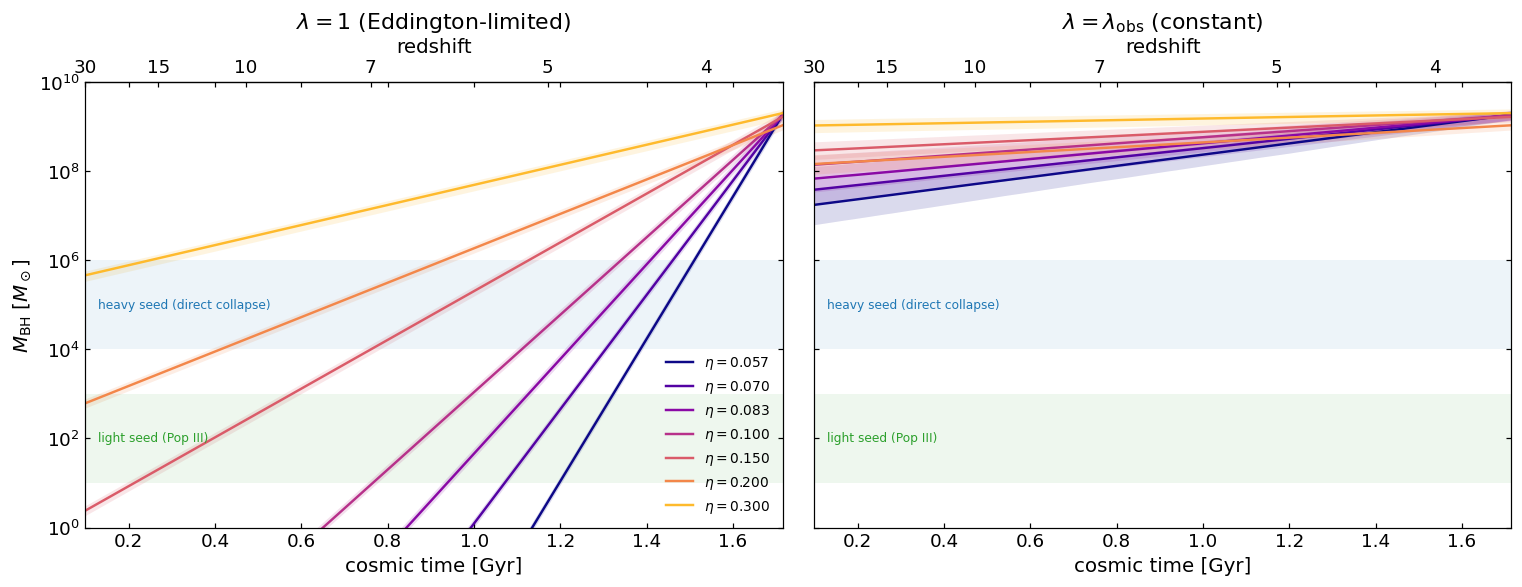

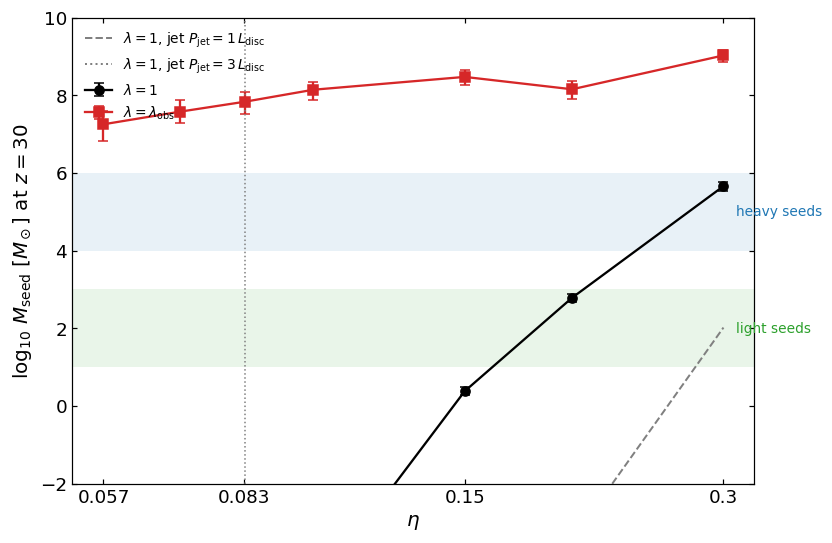

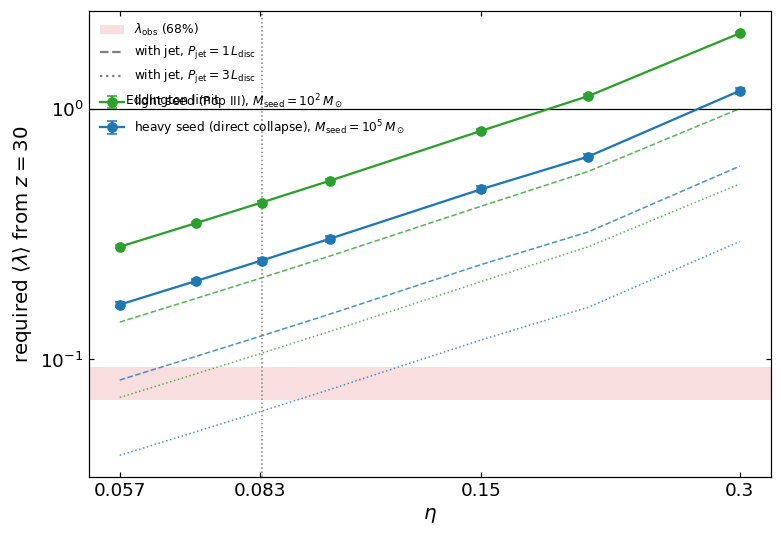

In [2]:
from astropy import units as u
try:
    from astropy.cosmology import Planck18 as cosmo
except ImportError:
    from astropy.cosmology import Planck15 as cosmo

# 1. constants and cosmic times
L_EDD_COEFF = 1.26e38                                     # erg/s per Msun (hydrogen)
T_EDD_GYR   = 1.989e33 * (2.998e10)**2 / L_EDD_COEFF / 3.156e16   # Gyr -> 0.449

Z_SEED   = 30.0                                           # seed formation redshift
SEEDS    = {'light seed (Pop III)': 1e2, 'heavy seed (direct collapse)': 1e5}
JET_R    = [1.0, 3.0]                                     # P_jet / L_disc (placeholder until notebook 5)

t_obs  = cosmo.age(Z_SOURCE).to(u.Gyr).value
t_seed = cosmo.age(Z_SEED).to(u.Gyr).value
dt     = t_obs - t_seed
print(f"t_Edd = {T_EDD_GYR:.3f} Gyr")
print(f"age at z = {Z_SOURCE:.2f}: {t_obs:.3f} Gyr,  at z = {Z_SEED:.0f}: {t_seed:.3f} Gyr  ->  dt = {dt:.3f} Gyr")

# 2. posterior samples of M_BH and lambda for every eta
post = {}
for eta in eta_grid:
    tag = eta_tag(eta) + '_7p'
    if not os.path.exists(f'chain_{tag}.npz'):
        print(f"missing chain: {tag}")
        continue
    d = np.load(f'chain_{tag}.npz')
    labels = list(d['labels'])
    M = d['samples'][:, labels.index('M_BH')]
    L = d['samples'][:, labels.index('L_Disk')]
    lam = L / (12 * eta) / (L_EDD_COEFF * M)
    post[eta] = {'M': M, 'lam': lam}
etas = list(post.keys())

def log10_seed(M, eta, lam, dt_gyr, boost=1.0):
    """log10 of the mass at dt_gyr before the observation, growing at constant lambda"""
    tau = eta / (1 - eta) * T_EDD_GYR / (lam * boost)
    return np.log10(M) - (dt_gyr / tau) / np.log(10)

def q(arr):
    return np.percentile(arr, [16, 50, 84])

# 3. table - e-folding times, seed masses, required lambda
rows = []
for eta in etas:
    M, lam = post[eta]['M'], post[eta]['lam']
    tau_edd = eta / (1 - eta) * T_EDD_GYR                     # e-folding time at lambda = 1
    row = {
        'eta':                f"{eta:.3f}",
        'M_BH [1e9]':         f"{np.median(M) / 1e9:.2f}",
        'lambda_obs':         f"{np.median(lam):.3f}",
        'tau(lam=1) [Myr]':   f"{1e3 * tau_edd:.0f}",
        'tau(lam_obs) [Myr]': f"{1e3 * np.median(tau_edd / lam):.0f}",
        'N_efold(lam=1)':     f"{dt / tau_edd:.1f}",
        'log M_seed (lam=1)':     "{:.1f} [{:.1f}, {:.1f}]".format(*np.roll(q(log10_seed(M, eta, 1.0, dt)), -1)[[0, 2, 1]][[0, 1, 2]] if False else q(log10_seed(M, eta, 1.0, dt))[[1, 0, 2]]),
        'log M_seed (lam_obs)':   "{:.1f} [{:.1f}, {:.1f}]".format(*q(log10_seed(M, eta, lam, dt))[[1, 0, 2]]),
    }
    for name, Ms in SEEDS.items():
        lam_req = eta / (1 - eta) * T_EDD_GYR / dt * np.log(M / Ms)
        row[f"<lam> req, {Ms:.0e}"] = "{:.2f} [{:.2f}, {:.2f}]".format(*q(lam_req)[[1, 0, 2]])
    rows.append(row)

growth_table = pd.DataFrame(rows)
print(f"\nGrowth from z = {Z_SEED:.0f} to z = {Z_SOURCE:.2f}  (median [16%, 84%])")
print(growth_table.to_string(index=False))
growth_table.to_csv('bh_growth_table.csv', index=False)

# 4. growth tracks M(t) for every eta - lambda = 1 and lambda = lambda_obs
#   tracks are drawn backwards from the observed mass; band = 68% from the posterior
t_grid = np.linspace(t_seed, t_obs, 300)
colors = plt.cm.plasma(np.linspace(0.0, 0.85, len(etas)))

# redshift <-> cosmic time for the top axis
z_tab = np.linspace(Z_SOURCE, 40, 400)
t_tab = cosmo.age(z_tab).to(u.Gyr).value
t_to_z = lambda t: np.interp(t, t_tab[::-1], z_tab[::-1])
z_to_t = lambda z: np.interp(z, z_tab, t_tab)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, mode in zip(axes, ['edd', 'obs']):
    for eta, col in zip(etas, colors):
        M, lam = post[eta]['M'], post[eta]['lam']
        lam_use = np.ones_like(M) if mode == 'edd' else lam
        sub = np.random.default_rng(1).choice(len(M), size=min(2000, len(M)), replace=False)
        logM_t = np.array([log10_seed(M[sub], eta, lam_use[sub], t_obs - t) for t in t_grid])
        lo, med, hi = np.percentile(logM_t, [16, 50, 84], axis=1)
        ax.fill_between(t_grid, 10**lo, 10**hi, color=col, alpha=0.15, lw=0)
        ax.semilogy(t_grid, 10**med, color=col, lw=1.6, label=rf'$\eta = {eta:.3f}$')

    for (name, Ms), (lo_s, hi_s), c in zip(SEEDS.items(), [(1e1, 1e3), (1e4, 1e6)], ['tab:green', 'tab:blue']):
        ax.axhspan(lo_s, hi_s, color=c, alpha=0.08, lw=0)
        ax.text(t_seed + 0.03, np.sqrt(lo_s * hi_s), name, fontsize=8, color=c, va='center')

    ax.set_xlim(t_seed, t_obs)
    ax.set_ylim(1, 1e10)
    ax.set_xlabel('cosmic time [Gyr]')
    ax.set_title(r'$\lambda = 1$ (Eddington-limited)' if mode == 'edd'
                 else r'$\lambda = \lambda_{\rm obs}$ (constant)')
    top = ax.secondary_xaxis('top', functions=(t_to_z, z_to_t))
    top.set_xticks([30, 15, 10, 7, 5, 4])
    top.set_xlabel('redshift')

axes[0].set_ylabel(r'$M_{\rm BH}$ [$M_\odot$]')
axes[0].legend(fontsize=9, frameon=False, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'bh_growth_tracks.png'), bbox_inches='tight')
plt.show()

# 5. seed mass at z = Z_SEED vs eta
fig, ax = plt.subplots(figsize=(8, 5.5))
for mode, col, mk, lab in [('edd', 'k', 'o', r'$\lambda = 1$'),
                           ('obs', 'tab:red', 's', r'$\lambda = \lambda_{\rm obs}$')]:
    meds, los, his = [], [], []
    for eta in etas:
        M, lam = post[eta]['M'], post[eta]['lam']
        lam_use = 1.0 if mode == 'edd' else lam
        lo, med, hi = q(log10_seed(M, eta, lam_use, dt))
        meds.append(med); los.append(med - lo); his.append(hi - med)
    ax.errorbar(etas, meds, yerr=[los, his], fmt=mk + '-', color=col, ms=6, capsize=3, label=lab)

# jet-assisted growth at lambda = 1 (placeholder P_jet/L_disc until notebook 5)
for r, ls in zip(JET_R, ['--', ':']):
    meds = [np.median(log10_seed(post[e]['M'], e, 1.0, dt, boost=1 + r)) for e in etas]
    ax.plot(etas, meds, ls=ls, color='gray', lw=1.3,
            label=rf'$\lambda = 1$, jet $P_{{\rm jet}} = {r:g}\,L_{{\rm disc}}$')

ax.axhspan(1, 3, color='tab:green', alpha=0.1, lw=0)
ax.axhspan(4, 6, color='tab:blue', alpha=0.1, lw=0)
ax.text(0.31, 2, 'light seeds', color='tab:green', fontsize=9, va='center')
ax.text(0.31, 5, 'heavy seeds', color='tab:blue', fontsize=9, va='center')
ax.axvline(1/12, color='gray', ls=':', lw=1)
ax.set_xscale('log')
ax.set_xticks([0.057, 0.083, 0.15, 0.3])
ax.set_xticklabels(['0.057', '0.083', '0.15', '0.3'])
ax.minorticks_off()
ax.set_ylim(-2, 10)
ax.set_xlabel(r'$\eta$')
ax.set_ylabel(rf'$\log_{{10}}\, M_{{\rm seed}}$ [$M_\odot$] at $z = {Z_SEED:.0f}$')
ax.legend(fontsize=9, frameon=False, loc='upper left')
plt.savefig(os.path.join(FIG_DIR, 'bh_seed_mass_vs_eta.png'), bbox_inches='tight')
plt.show()

# 6. average Eddington ratio required to grow from a seed at z = Z_SEED
fig, ax = plt.subplots(figsize=(8, 5.5))
for (name, Ms), col in zip(SEEDS.items(), ['tab:green', 'tab:blue']):
    meds, los, his = [], [], []
    for eta in etas:
        lam_req = eta / (1 - eta) * T_EDD_GYR / dt * np.log(post[eta]['M'] / Ms)
        lo, med, hi = q(lam_req)
        meds.append(med); los.append(med - lo); his.append(hi - med)
    ax.errorbar(etas, meds, yerr=[los, his], fmt='o-', color=col, ms=6, capsize=3,
                label=rf'{name}, $M_{{\rm seed}} = 10^{{{np.log10(Ms):.0f}}}\,M_\odot$')
    for r, ls in zip(JET_R, ['--', ':']):
        meds_j = [np.median(e / (1 - e) * T_EDD_GYR / dt * np.log(post[e]['M'] / Ms)) / (1 + r) for e in etas]
        ax.plot(etas, meds_j, ls=ls, color=col, lw=1.0, alpha=0.8)

# observed Eddington ratio (68% band over the grid)
lam_obs_all = np.concatenate([post[e]['lam'] for e in etas if not np.isclose(e, 0.2)])
ax.axhspan(*np.percentile(lam_obs_all, [16, 84]), color='tab:red', alpha=0.15, lw=0,
           label=r'$\lambda_{\rm obs}$ (68%)')
ax.axhline(1, color='k', ls='-', lw=0.8)
ax.text(0.058, 1.05, 'Eddington limit', fontsize=8)
ax.plot([], [], ls='--', color='gray', label=r'with jet, $P_{\rm jet} = 1\,L_{\rm disc}$')
ax.plot([], [], ls=':', color='gray', label=r'with jet, $P_{\rm jet} = 3\,L_{\rm disc}$')

ax.axvline(1/12, color='gray', ls=':', lw=1)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks([0.057, 0.083, 0.15, 0.3])
ax.set_xticklabels(['0.057', '0.083', '0.15', '0.3'])
ax.minorticks_off()
ax.set_xlabel(r'$\eta$')
ax.set_ylabel(r'required $\langle\lambda\rangle$ from $z = 30$')
ax.legend(fontsize=8, frameon=False, loc='upper left')
plt.savefig(os.path.join(FIG_DIR, 'bh_required_lambda_vs_eta.png'), bbox_inches='tight')
plt.show()

## Eddington-limited phase, then a decline to the observed λ


light seed (Pop III), M_seed = 1e+02 Msun
   eta | Edd. phase [Myr] | ends at z | M at switch
 0.057 |              356 |      10.3 |    4.95e+07
 0.070 |              474 |       8.7 |    1.20e+08
 0.083 |              599 |       7.5 |    2.30e+08
 0.100 |              767 |       6.3 |    4.68e+08
 0.150 |             1292 |       4.3 |    1.18e+09
 0.200 |       impossible |         - |           -
 0.300 |       impossible |         - |           -

heavy seed (direct collapse), M_seed = 1e+05 Msun
   eta | Edd. phase [Myr] | ends at z | M at switch
 0.057 |              153 |      15.7 |    2.76e+07
 0.070 |              219 |      13.3 |    6.53e+07
 0.083 |              291 |      11.5 |    1.23e+08
 0.100 |              393 |       9.7 |    2.59e+08
 0.150 |              693 |       6.8 |    6.22e+08
 0.200 |              949 |       5.5 |    4.65e+08
 0.300 |       impossible |         - |           -


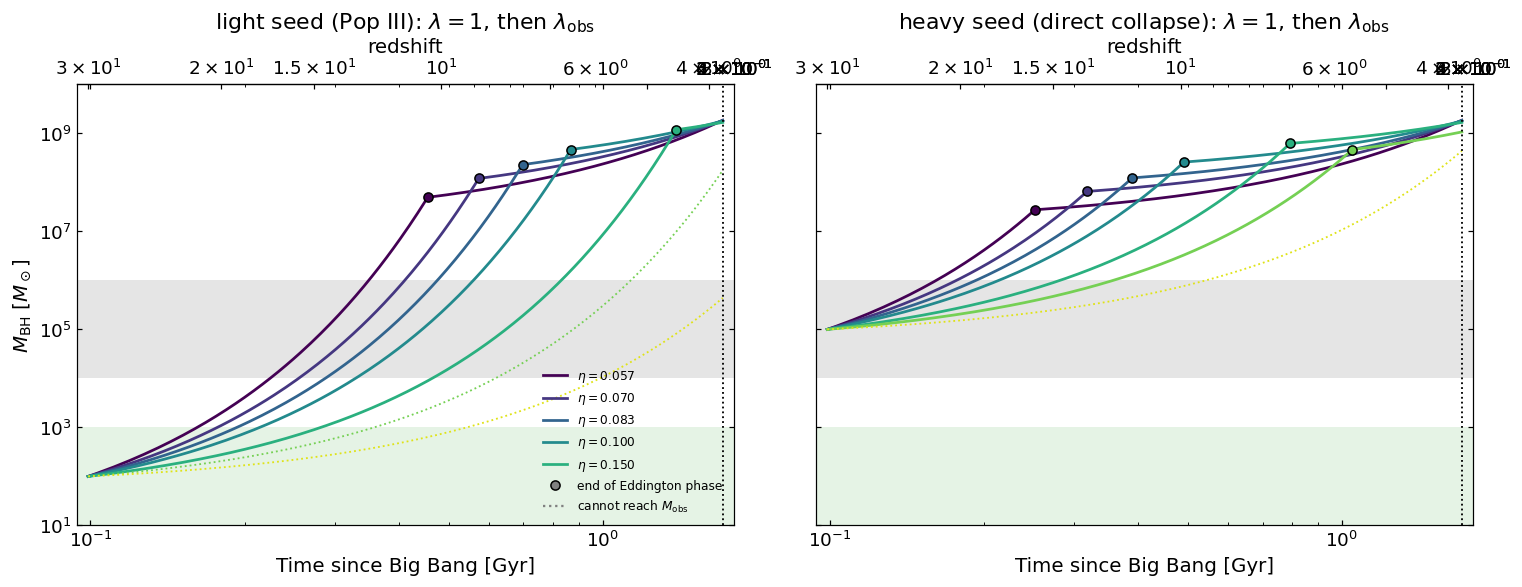

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
colors = plt.cm.viridis(np.linspace(0.0, 0.95, len(etas)))

for ax, (seed_name, M_seed) in zip(axes, SEEDS.items()):
    print(f"\n{seed_name}, M_seed = {M_seed:.0e} Msun")
    print(f"{'eta':>6s} | {'Edd. phase [Myr]':>16s} | {'ends at z':>9s} | {'M at switch':>11s}")
    for eta, col in zip(etas, colors):
        M_obs   = np.median(post[eta]['M'])
        lam_obs = np.median(post[eta]['lam'])
        need    = np.log(M_obs / M_seed) * eta / (1 - eta) * T_EDD_GYR    # required int(lambda dt) [Gyr]
        t1      = (need - lam_obs * dt) / (1 - lam_obs)                   # duration of Eddington phase

        if t1 > dt:
            print(f"{eta:6.3f} | {'impossible':>16s} | {'-':>9s} | {'-':>11s}")
            # show the lambda = 1 track for reference (does not reach M_obs)
            t_tr = np.linspace(t_seed, t_obs, 300)
            M_tr = M_seed * np.exp((1 - eta) / eta * (t_tr - t_seed) / T_EDD_GYR)
            ax.plot(t_tr, M_tr, color=col, lw=1.2, ls=':')
            continue

        t1 = max(t1, 0.0)
        t_sw = t_seed + t1
        t_tr = np.linspace(t_seed, t_obs, 400)
        growth = np.where(t_tr < t_sw,
                          (t_tr - t_seed),
                          t1 + lam_obs * (t_tr - t_sw))                   # int(lambda dt)
        M_tr = M_seed * np.exp((1 - eta) / eta * growth / T_EDD_GYR)
        M_sw = M_seed * np.exp((1 - eta) / eta * t1 / T_EDD_GYR)

        ax.plot(t_tr, M_tr, color=col, lw=1.8, label=rf'$\eta = {eta:.3f}$')
        ax.plot(t_sw, M_sw, 'o', color=col, ms=6, mec='k')
        print(f"{eta:6.3f} | {1e3 * t1:16.0f} | {t_to_z(t_sw):9.1f} | {M_sw:11.2e}")

    ax.axhspan(1e4, 1e6, color='0.75', alpha=0.4, lw=0)
    ax.axhspan(1e1, 1e3, color='tab:green', alpha=0.12, lw=0)
    ax.axvline(t_obs, color='k', ls=':', lw=1.2)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(t_seed * 0.95, t_obs * 1.05)
    ax.set_ylim(1e1, 1e10)
    ax.set_xlabel('Time since Big Bang [Gyr]')
    ax.set_title(rf'{seed_name}: $\lambda = 1$, then $\lambda_{{\rm obs}}$')
    top = ax.secondary_xaxis('top', functions=(t_to_z, z_to_t))
    top.set_xticks([30, 20, 15, 10, 7, 5, 4])
    top.set_xlabel('redshift')

axes[0].set_ylabel(r'$M_{\rm BH}$ [$M_\odot$]')
axes[0].plot([], [], 'o', color='gray', mec='k', label='end of Eddington phase')
axes[0].plot([], [], ':', color='gray', label=r'cannot reach $M_{\rm obs}$')
axes[0].legend(fontsize=8, frameon=False, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'bh_growth_eddington_then_decline.png'), bbox_inches='tight')
plt.show()

## Mass evolution and an exponentially declining Eddington ratio (heavy seeds)

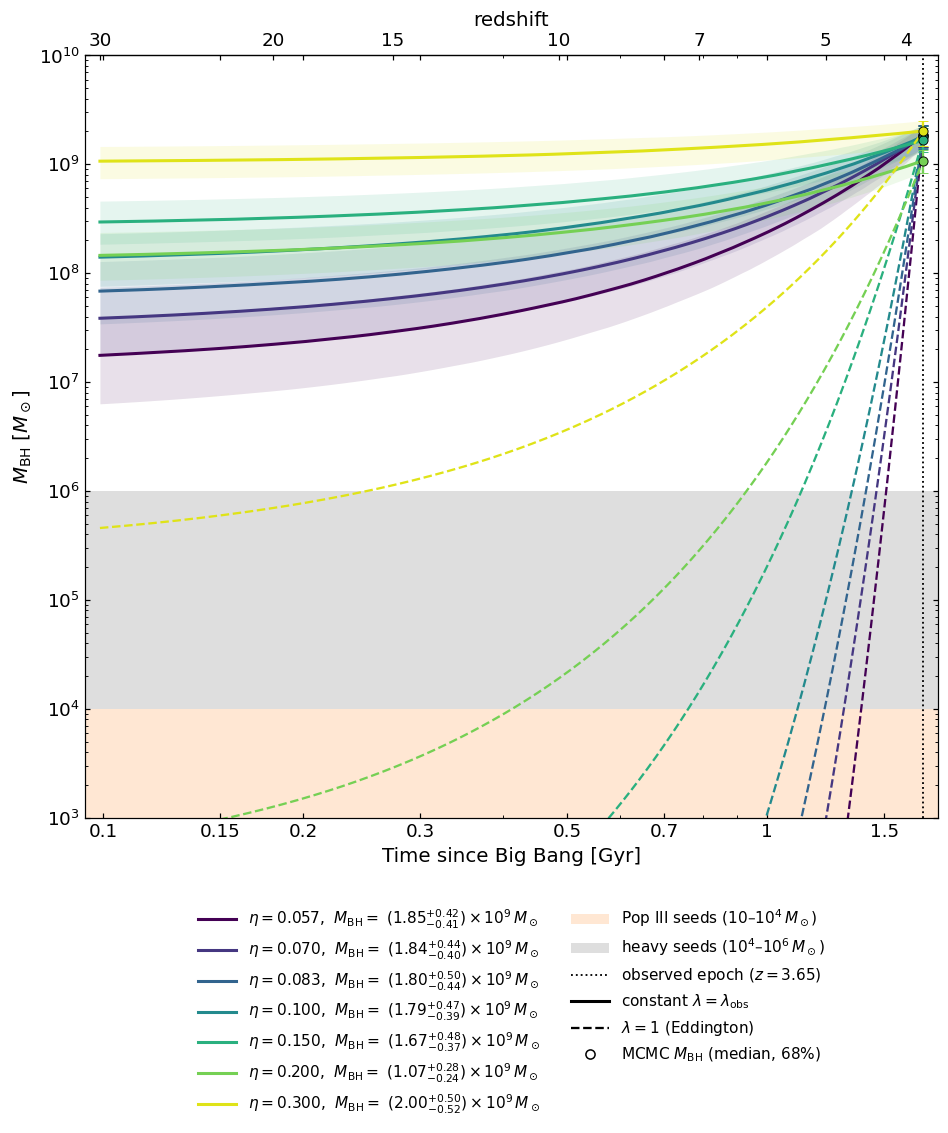

heavy seed, M_seed = 1e+05 Msun
   eta | tau_dec [Myr] | lam(z=30) | lam(z=10) | lam(z=6)
 0.057 |          1198 |      0.30 |      0.22 |     0.15
 0.070 |           982 |      0.42 |      0.29 |     0.18
 0.083 |           850 |      0.55 |      0.36 |     0.21
 0.100 |           710 |      0.77 |      0.45 |     0.24
 0.150 |           545 |      1.00 |      0.83 |     0.36
 0.200 |           519 |      1.00 |      1.00 |     0.64
 0.300 |   no solution


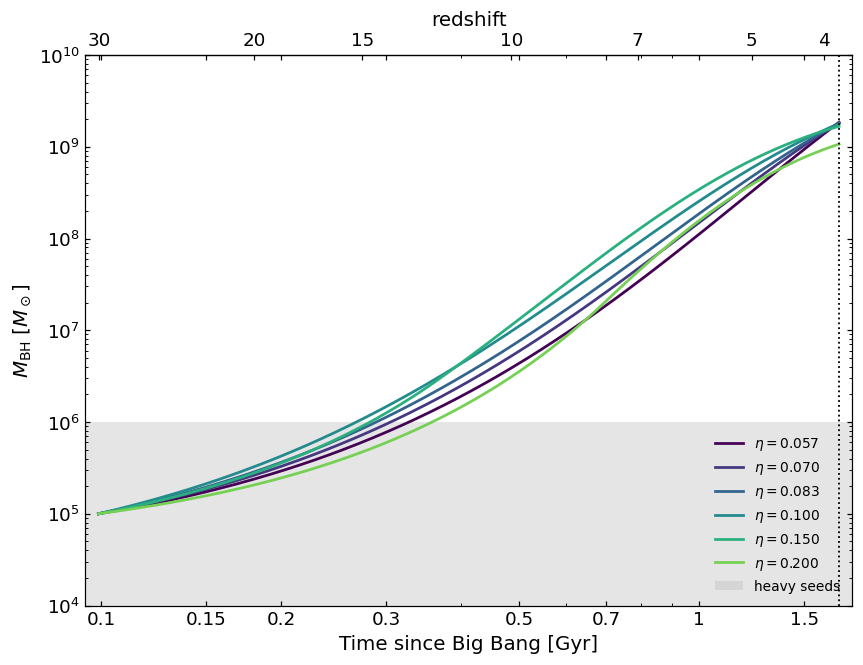

In [4]:
from scipy.optimize import brentq
from matplotlib.ticker import ScalarFormatter, NullLocator, FuncFormatter, NullFormatter

M_SEED_HEAVY = 1e5                                   # Msun, reference heavy seed
POP3_RANGE   = (1e1, 1e4)                            # Msun, Pop III remnant seeds
HEAVY_RANGE  = (1e4, 1e6)                            # Msun, heavy (DCBH) seeds
X_PAD        = 0.95                                  # same log-margin on both sides
T_TICKS      = [0.1, 0.15, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]   # Gyr
Z_TICKS      = [30, 20, 15, 10, 7, 5, 4]
colors = plt.cm.viridis(np.linspace(0.0, 0.95, len(etas)))

def clean_time_axes(ax):
    """log time axis (plain numbers, symmetric margins) with redshift axis on top"""
    ax.set_xscale('log')
    t_lo, t_hi = t_seed * X_PAD, t_obs / X_PAD
    ax.set_xlim(t_lo, t_hi)
    ax.set_xticks([t for t in T_TICKS if t_lo <= t <= t_hi])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:g}'))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel('Time since Big Bang [Gyr]')
    top = ax.secondary_xaxis('top', functions=(t_to_z, z_to_t))
    z_lo, z_hi = t_to_z(t_hi), t_to_z(t_lo)
    top.set_xticks([z for z in Z_TICKS if z_lo <= z <= z_hi])
    top.xaxis.set_major_formatter(ScalarFormatter())
    top.xaxis.set_minor_locator(NullLocator())
    top.set_xlabel('redshift')

def mass_label(M):
    """median and 68% interval as (a^{+b}_{-c}) x 10^e Msun"""
    lo, med, hi = np.percentile(M, [16, 50, 84])
    e = int(np.floor(np.log10(med)))
    s = 10.0**e
    return (rf'$({med/s:.2f}^{{+{(hi - med)/s:.2f}}}_{{-{(med - lo)/s:.2f}}})'
            rf'\times 10^{{{e}}}\,M_\odot$')

# Fig. 4.22: constant lambda_obs (solid, 68% band) and lambda = 1 (dashed)
t_grid_log = np.logspace(np.log10(t_seed), np.log10(t_obs), 300)
fig, ax = plt.subplots(figsize=(10, 9))

for eta, col in zip(etas, colors):
    M, lam = post[eta]['M'], post[eta]['lam']
    sub = np.random.default_rng(1).choice(len(M), size=min(2000, len(M)), replace=False)

    logM_obs = np.array([log10_seed(M[sub], eta, lam[sub], t_obs - t) for t in t_grid_log])
    lo, med, hi = np.percentile(logM_obs, [16, 50, 84], axis=1)
    ax.fill_between(t_grid_log, 10**lo, 10**hi, color=col, alpha=0.12, lw=0)
    ax.plot(t_grid_log, 10**med, color=col, lw=2.0,
            label=rf'$\eta = {eta:.3f}$,  $M_{{\rm BH}} = $ ' + mass_label(M))

    logM_edd = np.array([np.median(log10_seed(M, eta, 1.0, t_obs - t)) for t in t_grid_log])
    ax.plot(t_grid_log, 10**logM_edd, color=col, lw=1.5, ls='--')

    # observed BH mass from MCMC with 68% error bar
    M_lo, M_med, M_hi = np.percentile(M, [16, 50, 84])
    ax.errorbar(t_obs, M_med, yerr=[[M_med - M_lo], [M_hi - M_med]],
                fmt='o', color=col, mec='k', mew=0.6, ms=6, capsize=3, zorder=6)

ax.axhspan(*POP3_RANGE, color='tab:orange', alpha=0.18, lw=0,
           label=r'Pop III seeds ($10$–$10^4\,M_\odot$)')
ax.axhspan(*HEAVY_RANGE, color='0.75', alpha=0.5, lw=0,
           label=r'heavy seeds ($10^4$–$10^6\,M_\odot$)')
ax.axvline(t_obs, color='k', ls=':', lw=1.2, label=rf'observed epoch ($z = {Z_SOURCE:.2f}$)')
ax.plot([], [], color='k', lw=2.0, label=r'constant $\lambda = \lambda_{\rm obs}$')
ax.plot([], [], color='k', lw=1.5, ls='--', label=r'$\lambda = 1$ (Eddington)')
ax.plot([], [], 'o', color='w', mec='k', label=r'MCMC $M_{\rm BH}$ (median, 68%)')

clean_time_axes(ax)
ax.set_yscale('log')
ax.set_ylim(1e3, 1e10)
ax.set_ylabel(r'$M_{\rm BH}$ [$M_\odot$]')
ax.legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.10),
          ncol=2, frameon=False, columnspacing=2.0, handlelength=2.5)
plt.savefig(os.path.join(FIG_DIR, 'bh_mass_evolution.png'), bbox_inches='tight')
plt.show()

# Fig. 4.23: declining Eddington ratio, heavy seed only, mass growth only
#   lambda(t) = min[1, lambda_obs * exp((t_obs - t)/tau_dec)]
def lam_of_t(t, lam_obs, tau_dec):
    return np.minimum(1.0, lam_obs * np.exp((t_obs - t) / tau_dec))

def int_lambda(lam_obs, tau_dec):
    tt = np.linspace(t_seed, t_obs, 2000)
    return np.trapz(lam_of_t(tt, lam_obs, tau_dec), tt)

fig, ax = plt.subplots(figsize=(9, 6.5))
print(f"heavy seed, M_seed = {M_SEED_HEAVY:.0e} Msun")
print(f"{'eta':>6s} | {'tau_dec [Myr]':>13s} | {'lam(z=30)':>9s} | {'lam(z=10)':>9s} | {'lam(z=6)':>8s}")

for eta, col in zip(etas, colors):
    M_obs   = np.median(post[eta]['M'])
    lam_obs = np.median(post[eta]['lam'])
    need    = np.log(M_obs / M_SEED_HEAVY) * eta / (1 - eta) * T_EDD_GYR

    if need > dt:                                    # not reachable even at lambda = 1
        print(f"{eta:6.3f} | {'no solution':>13s}")
        continue
    tau_dec = brentq(lambda tau: int_lambda(lam_obs, tau) - need, 1e-3, 100.0)
    lam_z = [lam_of_t(z_to_t(z), lam_obs, tau_dec) for z in (30, 10, 6)]
    print(f"{eta:6.3f} | {1e3 * tau_dec:13.0f} | {lam_z[0]:9.2f} | {lam_z[1]:9.2f} | {lam_z[2]:8.2f}")

    tt = np.linspace(t_seed, t_obs, 400)
    lam_t = lam_of_t(tt, lam_obs, tau_dec)
    cum = np.concatenate([[0], np.cumsum(0.5 * (lam_t[1:] + lam_t[:-1]) * np.diff(tt))])
    M_t = M_SEED_HEAVY * np.exp((1 - eta) / eta * cum / T_EDD_GYR)
    ax.plot(tt, M_t, color=col, lw=1.8, label=rf'$\eta = {eta:.3f}$')

ax.axhspan(*HEAVY_RANGE, color='0.75', alpha=0.4, lw=0, label='heavy seeds')
ax.axvline(t_obs, color='k', ls=':', lw=1.2)
clean_time_axes(ax)
ax.set_yscale('log')
ax.set_ylim(1e4, 1e10)
ax.set_ylabel(r'$M_{\rm BH}$ [$M_\odot$]')
ax.legend(fontsize=9, frameon=False, loc='lower right')
plt.savefig(os.path.join(FIG_DIR, 'bh_growth_declining_lambda.png'), bbox_inches='tight')
plt.show()

## Exploratory: limited time at the Eddington limit

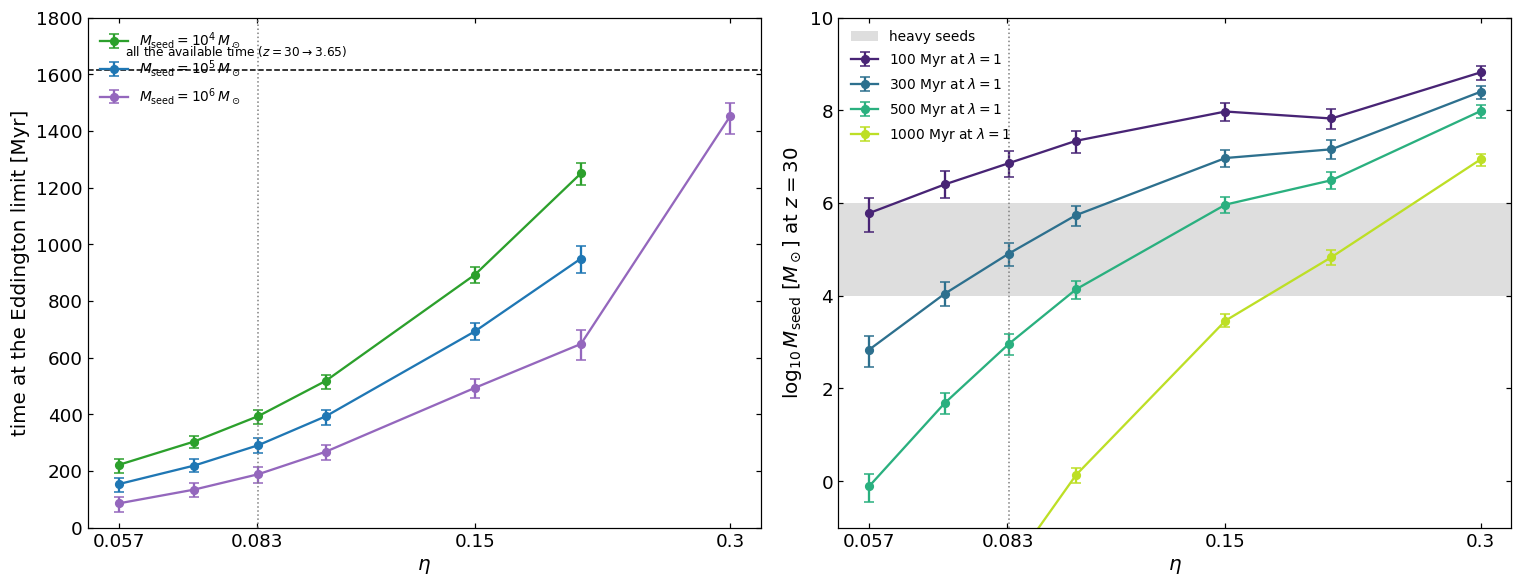

In [5]:
SEEDS_H = [1e4, 1e5, 1e6]
T_EDD_CAPS = [0.1, 0.3, 0.5, 1.0]                     # Gyr spent at lambda = 1

def t_edd_required(M, lam, eta, M_seed):
    """total time at lambda = 1 needed to grow M_seed into M [Gyr] (nan if impossible)"""
    need = eta / (1 - eta) * T_EDD_GYR * np.log(M / M_seed)
    T = (need - lam * dt) / (1 - lam)
    T = np.where(T > dt, np.nan, np.clip(T, 0, None))
    return T

def log_seed_capped(M, lam, eta, T_cap):
    """log10 seed mass needed if the Eddington phase lasts T_cap [Gyr]"""
    integral = T_cap + lam * (dt - T_cap)
    return np.log10(M) - (1 - eta) / eta * integral / T_EDD_GYR / np.log(10)

fig, (axl, axr) = plt.subplots(1, 2, figsize=(14, 5.5))

# ---- left: required time at the Eddington limit
for M_seed, col in zip(SEEDS_H, ['tab:green', 'tab:blue', 'tab:purple']):
    med, lo, hi = [], [], []
    for eta in etas:
        T = 1e3 * t_edd_required(post[eta]['M'], post[eta]['lam'], eta, M_seed)
        if np.mean(np.isnan(T)) > 0.5:
            med.append(np.nan); lo.append(np.nan); hi.append(np.nan); continue
        p16, p50, p84 = np.nanpercentile(T, [16, 50, 84])
        med.append(p50); lo.append(p50 - p16); hi.append(p84 - p50)
    axl.errorbar(etas, med, yerr=[lo, hi], fmt='o-', color=col, ms=5, capsize=3,
                 label=rf'$M_{{\rm seed}} = 10^{{{np.log10(M_seed):.0f}}}\,M_\odot$')
axl.axhline(1e3 * dt, color='k', lw=1, ls='--')
axl.text(0.058, 1e3 * dt * 1.03, rf'all the available time ($z = 30 \to {Z_SOURCE:.2f}$)', fontsize=8)
axl.set_ylabel(r'time at the Eddington limit [Myr]')
axl.set_ylim(0, 1800)

# ---- right: seed needed for a capped Eddington phase
cols = plt.cm.viridis(np.linspace(0.1, 0.9, len(T_EDD_CAPS)))
for T_cap, col in zip(T_EDD_CAPS, cols):
    med, lo, hi = [], [], []
    for eta in etas:
        p16, p50, p84 = np.percentile(log_seed_capped(post[eta]['M'], post[eta]['lam'], eta, T_cap),
                                      [16, 50, 84])
        med.append(p50); lo.append(p50 - p16); hi.append(p84 - p50)
    axr.errorbar(etas, med, yerr=[lo, hi], fmt='o-', color=col, ms=5, capsize=3,
                 label=rf'{1e3 * T_cap:.0f} Myr at $\lambda = 1$')
axr.axhspan(4, 6, color='0.75', alpha=0.5, lw=0, label='heavy seeds')
axr.set_ylabel(rf'$\log_{{10}} M_{{\rm seed}}$ [$M_\odot$] at $z = {Z_SEED:.0f}$')
axr.set_ylim(-1, 10)

for ax in (axl, axr):
    ax.set_xscale('log')
    ax.set_xticks([0.057, 0.083, 0.15, 0.3])
    ax.set_xticklabels(['0.057', '0.083', '0.15', '0.3'])
    ax.minorticks_off()
    ax.axvline(1/12, color='gray', ls=':', lw=1)
    ax.set_xlabel(r'$\eta$')
    ax.legend(fontsize=9, frameon=False, loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'bh_eddington_time_limit.png'), bbox_inches='tight')
plt.show()

## Eddington ratio pinned to the z ~ 6 quasar median

t_seed = 0.099 Gyr, t(z=6) = 0.929 Gyr, t_obs = 1.713 Gyr
tau_dec = 0.357 Gyr;  lambda = 1 until t = 0.812 Gyr
<lambda> = 0.645

--- no jets  (2P_jet/L_disc = 0.0) ---
  eta     a    eta_tot   M_seed(z=30)    M(z=6)
  0.057   0.00    0.06     4.24e-08     4.06e+05
  0.070   0.31    0.07     7.98e-05     2.12e+06
  0.083   0.51    0.08     1.42e-02     6.60e+06
  0.100   0.67    0.10     1.62e+00     1.87e+07
  0.150   0.89    0.15     3.63e+03     1.01e+08
  0.200   0.96    0.20     1.72e+05     2.36e+08
  0.300   1.00    0.30     8.13e+06     5.51e+08
  efficiency needed for a given seed:
    seed   1e+01 Msun:  eta = 0.109,  a = 0.73,  eta_tot = 0.11
    seed   1e+03 Msun:  eta = 0.138,  a = 0.86,  eta_tot = 0.14
    seed   1e+04 Msun:  eta = 0.161,  a = 0.91,  eta_tot = 0.16
    seed   1e+05 Msun:  eta = 0.191,  a = 0.95,  eta_tot = 0.19
    seed   1e+06 Msun:  eta = 0.236,  a = 0.98,  eta_tot = 0.24

--- N_H/N_e = 0.1, lower 68%  (2P_jet/L_disc = 2.9) ---
  eta     a    eta_tot   M

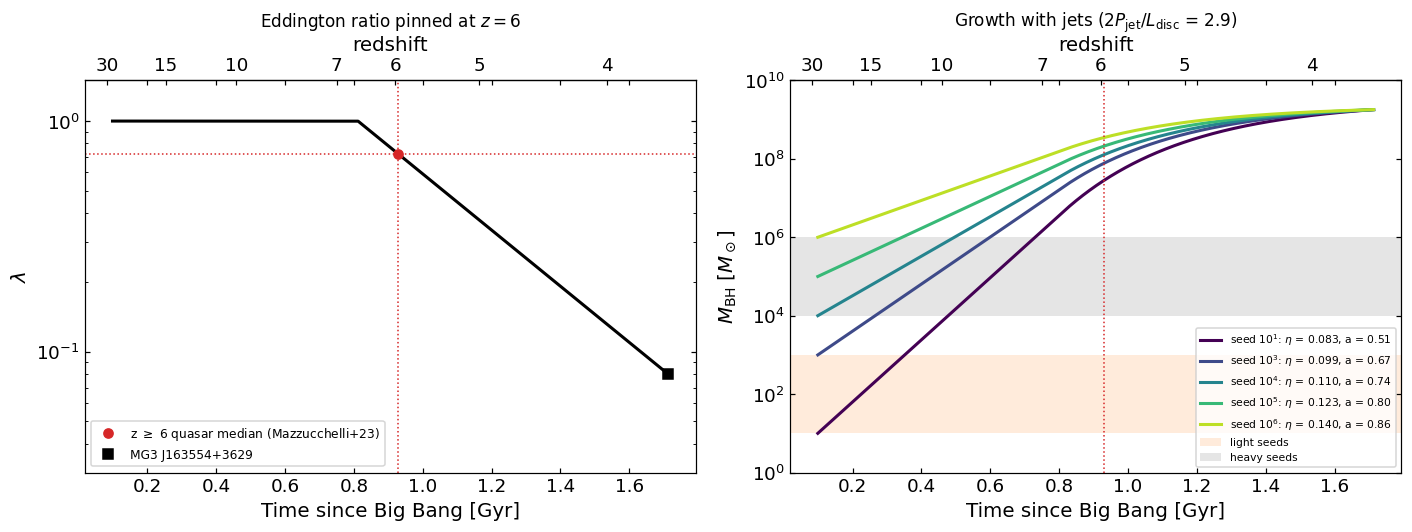

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import Planck18 as cosmo

# -------------------------- inputs --------------------------
M_OBS    = 1.8e9          # Msun, black hole mass at z_obs
LAM_OBS  = 0.08           # observed Eddington ratio
LAM_Z6   = 0.72           # median Eddington ratio of z > 6 quasars
TAU_ACC  = 0.450          # Gyr, sigma_T c / (4 pi G m_p)
Z_OBS, Z_6, Z_SEED = 3.65, 6.0, 30.0

eta_grid = [0.057, 0.070, 0.083, 0.100, 0.150, 0.200, 0.300]
seeds    = [1e1, 1e3, 1e4, 1e5, 1e6]                    # Msun

# 2 P_jet / L_disc for the jet scenarios (both jets)
jet_cases = {'no jets'                      : 0.0,
             'N_H/N_e = 0.1, lower 68%'     : 2.9,
             'N_H/N_e = 0.1, median'        : 4.0}

# spin needed to power the jets with a standard disk (Table 4.11): 2P_jet/L_disc -> a
R_bz = [0.9, 1.2, 2.2, 2.9, 4.0]
a_bz = [0.36, 0.42, 0.59, 0.69, 0.82]

# -------------------------- times --------------------------
t_seed = cosmo.age(Z_SEED).value
t_6    = cosmo.age(Z_6).value
t_obs  = cosmo.age(Z_OBS).value
tau_dec = (t_obs - t_6) / np.log(LAM_Z6 / LAM_OBS)

t   = np.linspace(t_seed, t_obs, 20001)
lam = np.minimum(1.0, LAM_OBS * np.exp((t_obs - t) / tau_dec))

# cumulative integral of lambda dt, measured backwards from t_obs
I_cum  = np.concatenate([[0.0], np.cumsum(0.5 * (lam[1:] + lam[:-1]) * np.diff(t))])
I_back = I_cum[-1] - I_cum                           # int_t^t_obs lambda dt'
I_tot  = I_back[0]
I_6    = np.interp(t_6, t, I_back)

print(f't_seed = {t_seed:.3f} Gyr, t(z=6) = {t_6:.3f} Gyr, t_obs = {t_obs:.3f} Gyr')
print(f'tau_dec = {tau_dec:.3f} Gyr;  lambda = 1 until t = {t_obs - tau_dec*np.log(1/LAM_OBS):.3f} Gyr')
print(f'<lambda> = {I_tot/(t_obs - t_seed):.3f}\n')

# -------------------------- spin <-> efficiency --------------------------
a_tab = np.linspace(0.0, 0.998, 5000)
Z1 = 1 + (1 - a_tab**2)**(1/3) * ((1 + a_tab)**(1/3) + (1 - a_tab)**(1/3))
Z2 = np.sqrt(3 * a_tab**2 + Z1**2)
r_isco = 3 + Z2 - np.sqrt((3 - Z1) * (3 + Z1 + 2 * Z2))       # in GM/c^2, prograde
eta_tab = 1 - np.sqrt(1 - 2 / (3 * r_isco))

# -------------------------- seed mass for each eta --------------------------
for label, R in jet_cases.items():
    print(f'--- {label}  (2P_jet/L_disc = {R}) ---')
    print('  eta     a    eta_tot   M_seed(z=30)    M(z=6)')
    for eta in eta_grid:
        eta_tot = eta * (1 + R)
        if eta_tot >= 1:
            continue
        k = (1 - eta_tot) / eta / TAU_ACC
        M_seed = M_OBS * np.exp(-k * I_tot)
        M_6    = M_OBS * np.exp(-k * I_6)
        a = np.interp(eta, eta_tab, a_tab)
        print(f'  {eta:5.3f}  {a:5.2f}   {eta_tot:5.2f}    {M_seed:9.2e}    {M_6:9.2e}')
    print('  efficiency needed for a given seed:')
    for M_seed in seeds:
        K = np.log(M_OBS / M_seed) * TAU_ACC / I_tot          # = (1 - eta_tot)/eta
        eta = 1 / (K + 1 + R)
        a = np.interp(eta, eta_tab, a_tab)
        print(f'    seed {M_seed:7.0e} Msun:  eta = {eta:.3f},  a = {a:.2f},  eta_tot = {eta*(1+R):.2f}')
    print()

# -------------------------- joint solution: growth spin = jet spin --------------------------
R_fine = np.linspace(R_bz[0], R_bz[-1], 2000)
a_jet  = np.interp(R_fine, R_bz, a_bz)
print('--- joint solution (growth spin = spin needed by the jets) ---')
for M_seed in seeds:
    K = np.log(M_OBS / M_seed) * TAU_ACC / I_tot
    eta_g = 1 / (K + 1 + R_fine)
    a_g   = np.interp(eta_g, eta_tab, a_tab)
    diff  = a_g - a_jet
    if np.all(diff > 0) or np.all(diff < 0):
        print(f'  seed {M_seed:7.0e} Msun: no crossing in 2P_jet/L_disc = {R_bz[0]}-{R_bz[-1]}')
        continue
    i = np.argmin(np.abs(diff))
    print(f'  seed {M_seed:7.0e} Msun:  2P_jet/L_disc = {R_fine[i]:.2f},  a = {a_jet[i]:.2f},  eta = {eta_g[i]:.3f}')

# -------------------------- figure --------------------------
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

ax = axs[0]
ax.plot(t, lam, 'k-', lw=2)
ax.axhline(LAM_Z6, color='tab:red', ls=':', lw=1)
ax.axvline(t_6, color='tab:red', ls=':', lw=1)
ax.plot(t_6, LAM_Z6, 'o', color='tab:red', label=r'z $\geq$ 6 quasar median (Mazzucchelli+23)')
ax.plot(t_obs, LAM_OBS, 's', color='k', label='MG3 J163554+3629')
ax.set_xlabel('Time since Big Bang [Gyr]'); ax.set_ylabel(r'$\lambda$')
ax.set_yscale('log'); ax.set_ylim(0.03, 1.5); ax.legend(fontsize=8)
ax.set_title(r'Eddington ratio pinned at $z = 6$', fontsize=11)

ax = axs[1]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(seeds)))
R_plot = jet_cases['N_H/N_e = 0.1, lower 68%']
for M_seed, col in zip(seeds, colors):
    K = np.log(M_OBS / M_seed) * TAU_ACC / I_tot
    eta = 1 / (K + 1 + R_plot)
    k = (1 - eta * (1 + R_plot)) / eta / TAU_ACC
    M_t = M_OBS * np.exp(-k * I_back)
    a = np.interp(eta, eta_tab, a_tab)
    ax.plot(t, M_t, color=col, lw=2, label=rf'seed $10^{{{np.log10(M_seed):.0f}}}$: $\eta$ = {eta:.3f}, a = {a:.2f}')
ax.axhspan(1e1, 1e3, color='tab:orange', alpha=0.15, lw=0, label='light seeds')
ax.axhspan(1e4, 1e6, color='grey', alpha=0.2, lw=0, label='heavy seeds')
ax.axvline(t_6, color='tab:red', ls=':', lw=1)
ax.set_xlabel('Time since Big Bang [Gyr]'); ax.set_ylabel(r'$M_{\rm BH}$ [$M_\odot$]')
ax.set_yscale('log'); ax.set_ylim(1, 1e10); ax.legend(fontsize=7, loc='lower right')
ax.set_title(rf'Growth with jets ($2P_{{\rm jet}}/L_{{\rm disc}}$ = {R_plot})', fontsize=11)

# redshift on the top axis (interpolation, no z_at_value)
z_grid = np.logspace(np.log10(2.0), np.log10(60.0), 2000)[::-1]
t_grid = cosmo.age(z_grid).value
for ax in axs:
    top = ax.secondary_xaxis('top', functions=(lambda tt: np.interp(tt, t_grid, z_grid),
                                               lambda zz: np.interp(zz, z_grid[::-1], t_grid[::-1])))
    top.set_xticks([30, 15, 10, 7, 6, 5, 4]); top.set_xlabel('redshift')

plt.tight_layout()
plt.savefig('BH_growth_pinned_z6.png', dpi=150, bbox_inches='tight')
plt.show()